# 02 · Experimentos de Privacidad Diferencial y Equidad

**Objetivo:** medir cuánto cuesta proteger a los estudiantes con $\epsilon$-DP, tanto en utilidad (AUC del modelo de alerta temprana, error de consultas agregadas) como en equidad (brechas entre `disability = 'Y'` y `'N'`, y entre deciles `imd_band`). Con esa evidencia se elige un $\epsilon$ para el sistema.

**Estructura:**
1. Baseline sin privacidad y auditoría de equidad.
2. Prueba de fuga de *proxies* ($I(A;X) > 0$).
3. DP en consultas agregadas (Laplace) y en el modelo (`diffprivlib`).
4. Barrido de $\epsilon$, trilema privacidad–utilidad–equidad y selección del $\epsilon$ óptimo.

In [1]:
import os
import sqlite3
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from diffprivlib.mechanisms import Laplace
from diffprivlib.models import LogisticRegression as DPLogisticRegression
from fairlearn.metrics import MetricFrame, false_positive_rate, selection_rate, true_positive_rate
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

SEED = 42
DB_PATH = "../db/oulad_proyecto.db"
FIG_DIR = "../docs/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

con = sqlite3.connect(DB_PATH)
df = pd.read_sql("SELECT * FROM oulad_analitico", con)
print(f"Matrículas: {len(df):,} | Estudiantes: {df['id_student'].nunique():,} | Tasa base de aprobación: {df['target_aprobado'].mean():.3f}")

Matrículas: 32,593 | Estudiantes: 28,785 | Tasa base de aprobación: 0.472


## 1. Preparación y baseline sin privacidad

**Decisiones de preprocesamiento (pensadas para que la DP sea válida):**
- **Atributos excluidos del modelo:** `disability`, por ser un dato sensible de salud (minimización, Ley 29733, Art. 8), y `final_result`, que es la etiqueta. `disability` se conserva **solo para auditar** la equidad. En la sección 2 se verifica si su exclusión protege realmente (*fairness through unawareness*).
- **Acotamiento con límites públicos fijados a priori.** Cada variable numérica se recorta a un dominio definido por conocimiento del dominio, no por los datos, y se escala a $[0,1]$. Si se usaran el mínimo/máximo empíricos (p. ej. `StandardScaler`), el preprocesamiento mismo filtraría información y anularía la garantía DP.
- **Partición agrupada por estudiante** (`StratifiedGroupKFold`): un mismo estudiante no aparece a la vez en *train* y *test*.
- **Acotamiento de contribución** (*contribution bounding*; Wilson et al., 2020): en entrenamiento se conserva **una matrícula por estudiante**, así la garantía DP es por **persona** y no por fila.

In [2]:
CAT = ["code_module", "code_presentation", "gender", "region", "highest_education", "imd_band", "age_band"]

# Límites de dominio públicos (no derivados de los datos): (mín, máx, transformación).
LIMITES = {
    "num_of_prev_attempts": (0, 6, None),
    "studied_credits": (0, 400, None),
    "date_registration": (-300, 60, None),
    "promedio_notas_60d": (0, 100, None),
    "entregas_60d": (0, 15, None),
    "retraso_promedio_60d": (-60, 60, None),
    "total_clics_60d": (0, np.log1p(10_000), np.log1p),
    "dias_activos_60d": (0, 90, None),
}
NUM = list(LIMITES)
CATEGORIAS = {c: sorted(df[c].unique()) for c in CAT}   # esquema público del dataset

def preparar(d: pd.DataFrame) -> pd.DataFrame:
    partes = []
    for c, (lo, hi, f) in LIMITES.items():
        x = d[c].astype(float)
        x = f(x.clip(lower=0)) if f is not None else x
        partes.append(((x.clip(lo, hi) - lo) / (hi - lo)).rename(c))
    for c in CAT:
        partes.append(pd.get_dummies(pd.Categorical(d[c], categories=CATEGORIAS[c]), prefix=c, dtype=float)
                      .set_index(d.index))
    return pd.concat(partes, axis=1)

X_all = preparar(df)
y_all = df["target_aprobado"].to_numpy()

# Norma L2 máxima analítica: cada numérica aporta ≤1 y cada grupo one-hot exactamente 1.
DATA_NORM = float(np.sqrt(len(NUM) + len(CAT)))
print(f"Dimensión: {X_all.shape[1]} | data_norm analítico = √({len(NUM)}+{len(CAT)}) = {DATA_NORM:.3f} "
      f"| norma máxima observada = {np.linalg.norm(X_all, axis=1).max():.3f}")

Dimensión: 53 | data_norm analítico = √(8+7) = 3.873 | norma máxima observada = 3.336


In [3]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_te = next(sgkf.split(X_all, y_all, groups=df["id_student"]))

train = df.iloc[idx_tr]
train_b = train.groupby("id_student", group_keys=False).sample(n=1, random_state=SEED)   # 1 matrícula por persona
test = df.iloc[idx_te]

X_tr, y_tr = X_all.loc[train_b.index].to_numpy(), train_b["target_aprobado"].to_numpy()
X_te, y_te = X_all.loc[test.index].to_numpy(), test["target_aprobado"].to_numpy()
dis_te = test["disability"].to_numpy()
imd_te = test["imd_band"].to_numpy()

print(f"Train (acotado): {len(X_tr):,} | Test: {len(X_te):,} | "
      f"solapamiento de estudiantes: {len(set(train['id_student']) & set(test['id_student']))}")
print(f"disability='Y' en test: {(dis_te == 'Y').sum():,} ({(dis_te == 'Y').mean():.1%})")

Train (acotado): 23,029 | Test: 6,489 | solapamiento de estudiantes: 0
disability='Y' en test: 605 (9.3%)


In [4]:
base = LogisticRegression(max_iter=3000, C=1.0)
base.fit(X_tr, y_tr)
p_base = base.predict_proba(X_te)[:, 1]
yhat_base = (p_base >= 0.5).astype(int)

metricas_base = pd.Series({
    "AUC": roc_auc_score(y_te, p_base),
    "Accuracy": accuracy_score(y_te, yhat_base),
    "F1": f1_score(y_te, yhat_base),
}).round(4)
metricas_base.to_frame("Baseline (sin DP)").T

,AUC,Accuracy,F1
Baseline (sin DP),0.8766,0.7946,0.7965


### Métricas de equidad desagregadas

En este sistema la clase positiva es **"aprobará"**. Por eso la lectura operativa de los errores es:
- **Tasa de aprobación predicha** (*selection rate*): proporción del grupo que el modelo considera fuera de riesgo.
- **TPR:** aprobadores correctamente reconocidos. Un TPR bajo significa **alertas innecesarias**, que estigmatizan y consumen recursos de tutoría.
- **FPR:** estudiantes que desaprobarán pero el modelo predice que aprueban. Un FPR alto significa **alertas omitidas**: el estudiante en riesgo no recibe ayuda. Es el error más dañino.
- **Disparate Impact (regla de los 4/5):** $DI = \frac{\text{tasa predicha del grupo}}{\text{tasa predicha del grupo de referencia}}$. Si $DI < 0.8$ hay indicio de impacto dispar (EEOC, 1978; Feldman et al., 2015).
- **Calibración:** se compara la probabilidad media predicha con la tasa real y se reporta el *Expected Calibration Error* (ECE, 10 bins).

In [5]:
def ece(y, p, bins=10):
    cortes = np.minimum((p * bins).astype(int), bins - 1)
    return sum(abs(y[cortes == b].mean() - p[cortes == b].mean()) * (cortes == b).mean()
               for b in range(bins) if (cortes == b).any())

def auditoria_equidad(y, yhat, p, grupo, referencia=None):
    mf = MetricFrame(
        metrics={"n": lambda yt, yp: len(yt), "tasa_real": lambda yt, yp: yt.mean(),
                 "tasa_predicha": selection_rate, "TPR": true_positive_rate, "FPR": false_positive_rate},
        y_true=y, y_pred=yhat, sensitive_features=grupo,
    )
    t = mf.by_group.copy()
    s = pd.Series(grupo)
    t["prob_media"] = [p[(s == g).to_numpy()].mean() for g in t.index]
    t["ECE"] = [ece(y[(s == g).to_numpy()], p[(s == g).to_numpy()]) for g in t.index]
    ref = referencia if referencia is not None else t["tasa_predicha"].idxmax()
    t["DI"] = t["tasa_predicha"] / t.loc[ref, "tasa_predicha"]
    t["cumple_4/5"] = np.where(t["DI"] >= 0.8, "sí", "NO")
    return t.round(3)

eq_dis = auditoria_equidad(y_te, yhat_base, p_base, dis_te, referencia="N")
eq_dis

,n,tasa_real,tasa_predicha,TPR,FPR,prob_media,ECE,DI,cumple_4/5
sensitive_feature_0,,,,,,,,,
N,5884.0,0.491,0.540,0.840,0.252,0.486,0.013,1.000,sí
Y,605.0,0.374,0.426,0.819,0.193,0.420,0.057,0.789,NO


In [6]:
eq_imd = auditoria_equidad(y_te, yhat_base, p_base, imd_te)
eq_imd

,n,tasa_real,tasa_predicha,TPR,FPR,prob_media,ECE,DI,cumple_4/5
sensitive_feature_0,,,,,,,,,
0-10%,656.0,0.319,0.323,0.684,0.154,0.338,0.037,0.413,NO
10-20,687.0,0.392,0.397,0.751,0.170,0.386,0.051,0.508,NO
20-30%,722.0,0.413,0.440,0.805,0.184,0.416,0.043,0.563,NO
30-40%,709.0,0.522,0.554,0.830,0.254,0.498,0.049,0.709,NO
40-50%,594.0,0.453,0.507,0.829,0.240,0.457,0.044,0.648,NO
50-60%,638.0,0.508,0.547,0.861,0.223,0.496,0.049,0.700,NO
60-70%,569.0,0.520,0.592,0.865,0.297,0.528,0.031,0.757,NO
70-80%,596.0,0.525,0.565,0.824,0.279,0.500,0.039,0.723,NO
80-90%,585.0,0.542,0.655,0.890,0.377,0.565,0.045,0.837,sí


In [7]:
brecha_base = {
    "TPR": eq_dis.loc["N", "TPR"] - eq_dis.loc["Y", "TPR"],
    "FPR": eq_dis.loc["N", "FPR"] - eq_dis.loc["Y", "FPR"],
}
auc_grupo_base = {g: roc_auc_score(y_te[dis_te == g], p_base[dis_te == g]) for g in ["N", "Y"]}
print(f"Brecha TPR (N − Y): {brecha_base['TPR']:+.3f} | Brecha FPR (N − Y): {brecha_base['FPR']:+.3f}")
print(f"AUC por grupo: N = {auc_grupo_base['N']:.3f} | Y = {auc_grupo_base['Y']:.3f}")
print(f"Tasa base real: N = {eq_dis.loc['N', 'tasa_real']:.3f} | Y = {eq_dis.loc['Y', 'tasa_real']:.3f}")

Brecha TPR (N − Y): +0.021 | Brecha FPR (N − Y): +0.059
AUC por grupo: N = 0.876 | Y = 0.876
Tasa base real: N = 0.491 | Y = 0.374


**Lectura del baseline:**
- **Discapacidad:** la AUC es igual en ambos grupos, así que el modelo **ordena** igual de bien. Sin embargo, $DI = 0.79 < 0.8$: el modelo predice aprobación con menos frecuencia para `disability = 'Y'`, lo que **incumple la regla de los 4/5**. Esto refleja en gran parte una diferencia real de tasa base (0.374 vs. 0.491, cociente ≈ 0.76).
- **Calibración:** para el grupo `Y` el ECE es ≈ 4 veces mayor (0.057 vs. 0.013). Las probabilidades que ven los tutores son **menos fiables** justamente para estudiantes con discapacidad.
- **Nivel socioeconómico:** el impacto dispar es mucho mayor. El decil más pobre obtiene $DI = 0.41$ y su FPR (0.154) es menor que el de los deciles ricos (0.380). Aquí el modelo tiende a errar **hacia alertar de más** a los pobres y **alertar de menos** a los ricos.
- **Ambigüedad del daño:** en un sistema de apoyo, recibir más alertas significa más tutoría, no una sanción. Un $DI$ bajo no es automáticamente perjudicial. Pasa a serlo si la alerta se usa para restringir oportunidades o si estigmatiza. Por eso el Model Card debe **prohibir usos punitivos**.

**Teorema de imposibilidad (Kleinberg et al., 2016; Chouldechova, 2017).** Las tasas base de aprobación difieren entre grupos (ver `tasa_real`). En esa situación ningún clasificador imperfecto puede cumplir a la vez **calibración por grupo** y **balance de errores** (TPR/FPR iguales). Elegir qué métrica priorizar es una decisión **normativa**. Para un sistema de alerta temprana, cuyo propósito es ofrecer apoyo, se propone priorizar el **balance de FPR**: que ningún grupo tenga más alertas omitidas que otro.

## 2. Prueba de fuga de *proxies*: ¿basta con eliminar `disability`?

*Fairness through unawareness* supone que, sin el atributo protegido $A$ entre las variables, el modelo no puede discriminar por él. Esto falla si las variables restantes $X$ contienen información sobre $A$, es decir, si $I(A;X) > 0$.

**Prueba:** se entrena un clasificador auxiliar $g: X_{\text{comportamiento}} \rightarrow A$ usando **solo** variables de actividad académica, sin demografía. Si $\text{AUC}(g) > 0.5$ de forma consistente (comparado con un control de etiquetas permutadas), las variables de comportamiento actúan como *proxy* del atributo protegido.

In [8]:
X_COMP = ["promedio_notas_60d", "entregas_60d", "retraso_promedio_60d",
          "total_clics_60d", "dias_activos_60d", "studied_credits"]
Xc = df[X_COMP].to_numpy()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rng = np.random.default_rng(SEED)

def prueba_proxy(a: np.ndarray, nombre: str) -> dict:
    res = {"atributo_protegido": nombre, "prevalencia": round(a.mean(), 3)}
    for etiqueta, modelo in [("LogReg", LogisticRegression(max_iter=3000)),
                             ("GradBoost", HistGradientBoostingClassifier(random_state=SEED))]:
        X_in = (Xc - Xc.mean(0)) / Xc.std(0) if etiqueta == "LogReg" else Xc
        p = cross_val_predict(modelo, X_in, a, cv=cv, groups=df["id_student"], method="predict_proba")[:, 1]
        res[f"AUC_{etiqueta}"] = round(roc_auc_score(a, p), 3)
    a_perm = rng.permutation(a)
    p0 = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), Xc, a_perm,
                           cv=cv, groups=df["id_student"], method="predict_proba")[:, 1]
    res["AUC_control_permutado"] = round(roc_auc_score(a_perm, p0), 3)
    res["I(A;X)_nats_suma_marginales"] = round(mutual_info_classif(Xc, a, random_state=SEED).sum(), 4)
    return res

proxies = pd.DataFrame([
    prueba_proxy((df["disability"] == "Y").astype(int).to_numpy(), "disability = 'Y'"),
    prueba_proxy(df["imd_band"].isin(["0-10%", "10-20", "20-30%"]).astype(int).to_numpy(), "imd_band ≤ 30% (pobreza)"),
])
proxies

,atributo_protegido,prevalencia,AUC_LogReg,AUC_GradBoost,AUC_control_permutado,I(A;X)_nats_suma_marginales
0,disability = 'Y',0.097,0.564,0.585,0.498,0.0183
1,imd_band ≤ 30% (pobreza),0.322,0.577,0.582,0.502,0.0383


In [9]:
mi = pd.Series(mutual_info_classif(Xc, (df["disability"] == "Y").astype(int), random_state=SEED),
               index=X_COMP, name="I(disability; X_j) [nats]").sort_values(ascending=False)
mi.round(4).to_frame()

,I(disability; X_j) [nats]
studied_credits,0.0058
promedio_notas_60d,0.0042
dias_activos_60d,0.0041
entregas_60d,0.0027
retraso_promedio_60d,0.0014
total_clics_60d,0.0000


**Lectura:** el AUC de $g$ (≈ 0.56–0.59) queda consistentemente por encima del control permutado (≈ 0.50), y la información mutua es positiva. El patrón de actividad en los primeros 60 días contiene información sobre la condición de discapacidad y sobre el nivel socioeconómico ($I(A;X) > 0$). En consecuencia:
- Eliminar `disability` del modelo **no** garantiza equidad: el modelo puede reconstruir parcialmente la señal a través de los *proxies*. Por eso las brechas de la sección 1 existen aunque el atributo no esté entre las variables.
- La respuesta ética no es ocultar el atributo sino **medir** las brechas por subgrupo (lo que exige conservar `disability` en un entorno de auditoría con acceso restringido) y documentarlas en el Model Card.
- Que el AUC de $g$ sea moderado y no alto también es informativo: los *proxies* filtran señal, pero no permiten inferir la discapacidad de forma fiable a nivel individual.

## 3. Privacidad Diferencial

### 3.1 Fundamento

Un mecanismo $\mathcal{M}$ es $\epsilon$-DP si para cualquier par de bases $D, D'$ que difieren en **una persona** y todo resultado $S$ se cumple $P[\mathcal{M}(D) \in S] \le e^{\epsilon} P[\mathcal{M}(D') \in S]$ (Dwork, McSherry, Nissim y Smith, 2006). El **mecanismo de Laplace** publica $f(D) + \text{Lap}(\Delta f / \epsilon)$, donde la **sensibilidad global** es $\Delta f = \max_{D \sim D'} \lVert f(D) - f(D') \rVert_1$.

**Elección de `diffprivlib` (IBM; Holohan et al., 2019):**
- Es de código abierto, está revisada por pares y su API es compatible con `scikit-learn`.
- Implementa mecanismos con muestreo seguro frente a ataques de punto flotante (Mironov, 2012).
- Incluye modelos DP listos (`LogisticRegression` según Chaudhuri, Monteleoni y Sarwate, 2011) y un `BudgetAccountant` para la composición.
- Alternativas como OpenDP o Google DP están orientadas a consultas SQL y no ofrecen un clasificador DP equivalente con la misma API.

### 3.2 Consultas agregadas sobre estudiantes con consentimiento para investigación externa

La finalidad `investigacion_externa` tiene como base legal el **consentimiento expreso**. Solo entran a estas consultas los estudiantes con `otorgado = 1` y sin revocación. El modelo de alerta temprana (3.3), en cambio, usa a todos los estudiantes, amparado en la relación contractual educativa.

In [10]:
consent = pd.read_sql(
    "SELECT id_student FROM consent_receipts "
    "WHERE finalidad = 'investigacion_externa' AND otorgado = 1 AND revocado_en IS NULL", con)
q = df[df["id_student"].isin(consent["id_student"])]
q = q.groupby("id_student", group_keys=False).sample(n=1, random_state=SEED)   # 1 contribución por persona
print(f"Estudiantes con consentimiento activo: {len(consent):,} de {df['id_student'].nunique():,} "
      f"({len(consent) / df['id_student'].nunique():.1%}) | filas tras acotar contribución: {len(q):,}")

L, U = 0.0, 100.0                                 # dominio público de promedio_notas_60d
q = q.assign(nota_acotada=q["promedio_notas_60d"].clip(L, U))
verdad = q.groupby("region").agg(conteo=("id_student", "size"), suma=("nota_acotada", "sum"))
verdad["promedio"] = verdad["suma"] / verdad["conteo"]

DELTA_CONTEO = 1          # añadir/quitar una persona cambia un conteo en 1
DELTA_SUMA = U - L        # ... y una suma acotada en a lo sumo U − L = 100
print(f"Δf conteo = {DELTA_CONTEO} | Δf suma acotada = {DELTA_SUMA:.0f} "
      f"| promedio = suma_DP / conteo_DP (post-procesamiento, sin costo adicional de privacidad)")

Estudiantes con consentimiento activo: 18,780 de 28,785 (65.2%) | filas tras acotar contribución: 18,780
Δf conteo = 1 | Δf suma acotada = 100 | promedio = suma_DP / conteo_DP (post-procesamiento, sin costo adicional de privacidad)


**Cálculo de sensibilidad y presupuesto:**
- **Conteo por región:** cada persona aporta una sola fila (acotamiento de contribución) y pertenece a una sola región, por lo que $\Delta f_{conteo} = 1$.
- **Promedio acotado:** el promedio directo tiene una sensibilidad que depende de $n$, así que se descompone en suma y conteo. Con la nota acotada a $[0, 100]$, $\Delta f_{suma} = 100$. El cociente es **post-procesamiento**, que no consume presupuesto adicional.
- **Composición:** las 13 regiones son disjuntas (composición **paralela**, sin costo extra). Se publican dos estadísticos (conteo y suma), que se reparten $\epsilon/2$ cada uno (composición **secuencial**). Costo total: $\epsilon$.

In [11]:
def consulta_laplace(epsilon: float, semilla: int) -> pd.DataFrame:
    m_conteo = Laplace(epsilon=epsilon / 2, sensitivity=DELTA_CONTEO, random_state=semilla)
    m_suma = Laplace(epsilon=epsilon / 2, sensitivity=DELTA_SUMA, random_state=semilla + 10_000)
    r = verdad.copy()
    r["conteo_dp"] = [max(m_conteo.randomise(float(v)), 1.0) for v in r["conteo"]]
    r["suma_dp"] = [min(max(m_suma.randomise(float(v)), 0.0), U * c) for v, c in zip(r["suma"], r["conteo_dp"])]
    r["promedio_dp"] = r["suma_dp"] / r["conteo_dp"]
    return r

def error_relativo(r: pd.DataFrame) -> tuple[float, float]:
    e_c = (100 * (r["conteo_dp"] - r["conteo"]).abs() / r["conteo"]).mean()
    e_p = (100 * (r["promedio_dp"] - r["promedio"]).abs() / r["promedio"]).mean()
    return e_c, e_p

ejemplo = consulta_laplace(1.0, semilla=0)
print("Ejemplo con ε = 1.0 → error relativo medio: conteo = %.2f %% | promedio = %.2f %%" % error_relativo(ejemplo))
ejemplo[["conteo", "conteo_dp", "promedio", "promedio_dp"]].round(2)

Ejemplo con ε = 1.0 → error relativo medio: conteo = 0.14 % | promedio = 0.45 %


,conteo,conteo_dp,promedio,promedio_dp
region,,,,
East Anglian Region,1951,1949.74,57.75,58.02
East Midlands Region,1359,1357.43,57.33,57.63
Ireland,721,723.09,68.48,69.04
London Region,1817,1815.51,51.88,52.07
North Region,1036,1033.20,58.44,58.23
North Western Region,1681,1673.84,53.10,53.44
Scotland,1904,1903.59,64.21,64.25
South East Region,1197,1196.92,58.96,58.40
South Region,1797,1796.73,59.47,59.66


### 3.3 Modelo con DP: `diffprivlib.models.LogisticRegression`

El algoritmo (Chaudhuri et al., 2011) añade ruido calibrado a los coeficientes. Su sensibilidad depende de la norma L2 máxima de las filas, el parámetro `data_norm`:
- **Si se omite**, `diffprivlib` lo estima con los datos (`PrivacyLeakWarning`) y la garantía se rompe, porque la norma máxima depende de un individuo concreto.
- **Si se sobreestima**, la garantía se cumple pero se añade más ruido del necesario.
- **Justificación del valor usado:** gracias al preprocesamiento con límites públicos, cada variable numérica está en $[0,1]$ y cada grupo *one-hot* aporta exactamente un 1. Entonces $\lVert x \rVert_2 \le \sqrt{8 + 7} = \sqrt{15} \approx 3.873$. Es una cota **analítica, ajustada y que no depende de los datos**. Las filas que la excedieran se recortan, lo que preserva la garantía.

In [12]:
dp_demo = DPLogisticRegression(epsilon=1.0, data_norm=DATA_NORM, max_iter=3000, random_state=0)
dp_demo.fit(X_tr, y_tr)
p_demo = dp_demo.predict_proba(X_te)[:, 1]
print(f"DP-LogReg ε=1.0 → AUC = {roc_auc_score(y_te, p_demo):.4f} (baseline {metricas_base['AUC']:.4f})")

DP-LogReg ε=1.0 → AUC = 0.8081 (baseline 0.8766)


## 4. Barrido de $\epsilon$: privacidad, utilidad y equidad

Para cada $\epsilon \in \{0.1, 0.5, 1, 2, 5, 10\}$ se hacen **10 ejecuciones** con semillas distintas: el ruido es aleatorio y una sola corrida puede ser engañosa. Se registran:
- **Utilidad del modelo:** AUC, Accuracy y F1 globales, y AUC por grupo.
- **Utilidad de las consultas:** error relativo medio (%) del conteo y del promedio por región.
- **Equidad:** brecha $|N - Y|$ de TPR y FPR. Se verifica el efecto *the poor get poorer* (Bagdasaryan, Poursaeed y Shmatikov, 2019): ¿la DP degrada más al subgrupo minoritario?

In [13]:
EPSILONS = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
N_RUNS = 10
filas = []
for eps in EPSILONS:
    for run in range(N_RUNS):
        m = DPLogisticRegression(epsilon=eps, data_norm=DATA_NORM, max_iter=3000, random_state=run)
        m.fit(X_tr, y_tr)
        p = m.predict_proba(X_te)[:, 1]
        yhat = (p >= 0.5).astype(int)
        g = {}
        for grp in ["N", "Y"]:
            mk = dis_te == grp
            yt, yp = y_te[mk], yhat[mk]
            g[grp] = {"TPR": yp[yt == 1].mean(), "FPR": yp[yt == 0].mean(),
                      "AUC": roc_auc_score(yt, p[mk]) if len(np.unique(p[mk])) > 1 else 0.5}
        e_c, e_p = error_relativo(consulta_laplace(eps, semilla=run))
        filas.append({
            "epsilon": eps, "run": run,
            "AUC": roc_auc_score(y_te, p), "Accuracy": accuracy_score(y_te, yhat), "F1": f1_score(y_te, yhat, zero_division=0),
            "AUC_N": g["N"]["AUC"], "AUC_Y": g["Y"]["AUC"],
            "brecha_TPR": abs(g["N"]["TPR"] - g["Y"]["TPR"]), "brecha_FPR": abs(g["N"]["FPR"] - g["Y"]["FPR"]),
            "tasa_predicha": yhat.mean(),
            "err_conteo_%": e_c, "err_promedio_%": e_p,
        })

barrido = pd.DataFrame(filas)
media = barrido.groupby("epsilon").mean().drop(columns="run")
desv = barrido.groupby("epsilon").std().drop(columns="run")
media.round(4)

,AUC,Accuracy,F1,AUC_N,AUC_Y,brecha_TPR,brecha_FPR,tasa_predicha,err_conteo_%,err_promedio_%
epsilon,,,,,,,,,,
0.1,0.6249,0.5881,0.5786,0.6243,0.6241,0.0451,0.0434,0.4985,1.3068,3.3871
0.5,0.7714,0.7027,0.6932,0.7708,0.7730,0.0268,0.0346,0.4895,0.2614,0.6783
1.0,0.8171,0.7412,0.7363,0.8165,0.8184,0.0275,0.0282,0.5020,0.1307,0.3392
2.0,0.8226,0.7466,0.7421,0.8219,0.8248,0.0261,0.0266,0.5034,0.0653,0.1696
5.0,0.8743,0.7907,0.7924,0.8741,0.8735,0.0174,0.0544,0.5283,0.0261,0.0679
10.0,0.8762,0.7934,0.7951,0.8759,0.8754,0.0207,0.0568,0.5290,0.0131,0.0339


In [14]:
# Estilo de figura: fondo claro, una escala por panel, marcas finas y etiquetas directas.
SERIE_1, SERIE_2 = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": TINTA_2, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})

def eje_epsilon(ax):
    ax.set_xscale("log")
    ax.set_xticks(EPSILONS)
    ax.set_xticklabels([f"{e:g}" for e in EPSILONS])
    ax.minorticks_off()
    ax.set_xlim(0.075, 13.5)
    ax.set_xlabel("ε (presupuesto de privacidad; menor = más privado)")

def serie(ax, col, color, etiqueta, escala=1.0):
    mu, sd = media[col] * escala, desv[col] * escala
    ax.fill_between(EPSILONS, mu - sd, mu + sd, color=color, alpha=0.12, linewidth=0)
    ax.plot(EPSILONS, mu, color=color, marker="o", label=etiqueta)

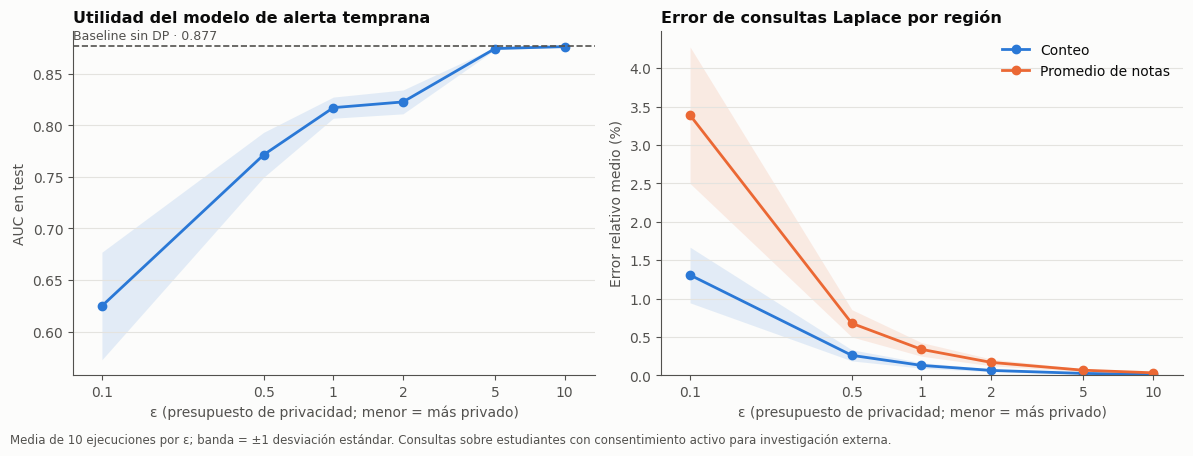

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

serie(ax1, "AUC", SERIE_1, "DP-LogReg")
ax1.axhline(metricas_base["AUC"], color=TINTA_2, linestyle="--", linewidth=1.2)
ax1.annotate(f"Baseline sin DP · {metricas_base['AUC']:.3f}", (0.075, metricas_base["AUC"]),
             xytext=(0, 5), textcoords="offset points", fontsize=9, color=TINTA_2)
eje_epsilon(ax1)
ax1.set_ylabel("AUC en test")
ax1.set_title("Utilidad del modelo de alerta temprana")

serie(ax2, "err_conteo_%", SERIE_1, "Conteo")
serie(ax2, "err_promedio_%", SERIE_2, "Promedio de notas")
eje_epsilon(ax2)
ax2.set_ylim(bottom=0)
ax2.set_ylabel("Error relativo medio (%)")
ax2.set_title("Error de consultas Laplace por región")
ax2.legend(loc="upper right")

fig.text(0.01, -0.02, f"Media de {N_RUNS} ejecuciones por ε; banda = ±1 desviación estándar. "
         "Consultas sobre estudiantes con consentimiento activo para investigación externa.",
         fontsize=8.5, color=TINTA_2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/curva_privacidad_utilidad.png", dpi=200, bbox_inches="tight")
plt.show()

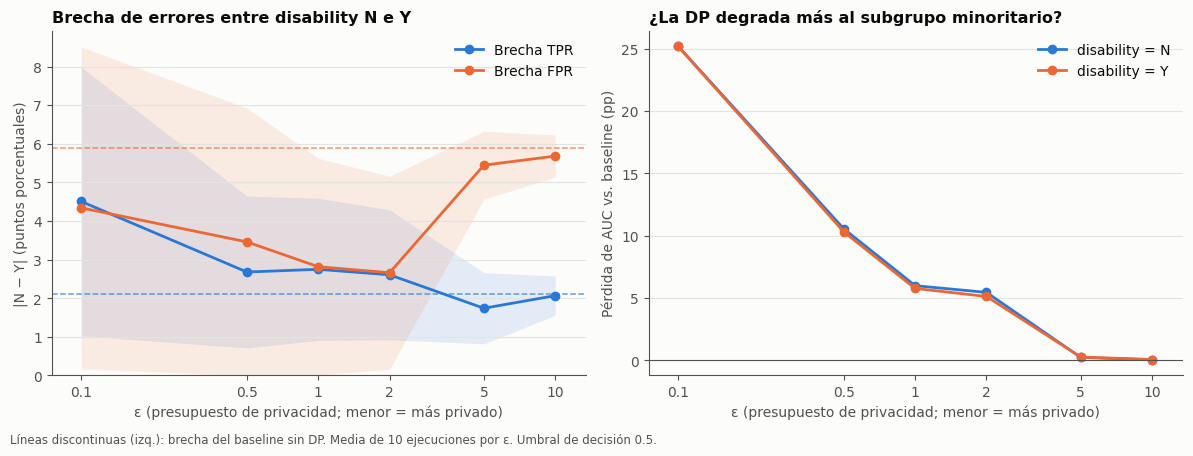

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))

serie(ax1, "brecha_TPR", SERIE_1, "Brecha TPR", escala=100)
serie(ax1, "brecha_FPR", SERIE_2, "Brecha FPR", escala=100)
for col, color in [("TPR", SERIE_1), ("FPR", SERIE_2)]:
    ax1.axhline(100 * abs(brecha_base[col]), color=color, linestyle="--", linewidth=1.1, alpha=0.7)
eje_epsilon(ax1)
ax1.set_ylim(bottom=0)
ax1.set_ylabel("|N − Y| (puntos porcentuales)")
ax1.set_title("Brecha de errores entre disability N e Y")
ax1.legend(loc="upper right")

caida_N = 100 * (auc_grupo_base["N"] - media["AUC_N"])
caida_Y = 100 * (auc_grupo_base["Y"] - media["AUC_Y"])
for caida, color, etq in [(caida_N, SERIE_1, "disability = N"), (caida_Y, SERIE_2, "disability = Y")]:
    ax2.plot(EPSILONS, caida, color=color, marker="o", label=etq)
ax2.axhline(0, color=TINTA_2, linewidth=0.8)
eje_epsilon(ax2)
ax2.set_ylabel("Pérdida de AUC vs. baseline (pp)")
ax2.set_title("¿La DP degrada más al subgrupo minoritario?")
ax2.legend(loc="upper right")

fig.text(0.01, -0.02, "Líneas discontinuas (izq.): brecha del baseline sin DP. "
         f"Media de {N_RUNS} ejecuciones por ε. Umbral de decisión 0.5.", fontsize=8.5, color=TINTA_2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/trilema_privacidad_equidad.png", dpi=200, bbox_inches="tight")
plt.show()

**Lectura de las figuras:**
- **Consultas agregadas:** son muy robustas. Incluso con $\epsilon = 0.1$, el error medio es ≤ 3.4 %, porque cada región agrupa más de 700 personas y el ruido ($\Delta f/\epsilon$) es pequeño frente a la señal. Para estadísticas de grupos grandes, la DP es prácticamente gratuita.
- **Modelo:** es mucho más sensible. Hasta $\epsilon = 2$ pierde 5–25 pp de AUC; desde $\epsilon = 5$ queda a < 0.3 pp del baseline. El modelo publica 53 coeficientes a la vez, y el ruido sobre ese vector se reparte entre todas las dimensiones.
- ***The poor get poorer* no se reproduce aquí.** La pérdida de AUC es prácticamente idéntica para `disability = N` e `Y` en todo el rango. Bagdasaryan et al. (2019) describen el efecto en **DP-SGD** con redes profundas, donde el recorte de gradientes perjudica a los ejemplos poco representados. `diffprivlib` usa perturbación de los coeficientes de un modelo lineal convexo, y el ruido afecta a todos por igual. Es un resultado negativo honesto: **depende del algoritmo DP elegido**.
- **"Equidad por degradación":** con $\epsilon$ bajo, la brecha de FPR **disminuye** (de 5.9 a 2.7–3.5 pp). No es una mejora real: el modelo se vuelve tan ruidoso que trata a todos de forma casi aleatoria. Las bandas son muy anchas y la AUC cae. Una brecha pequeña con utilidad destruida no es equidad.
- **La inequidad que persiste viene de los datos, no de la DP.** Con $\epsilon \geq 5$, las brechas vuelven a las del baseline (TPR ≈ 2 pp, FPR ≈ 5.5 pp). La DP ni las crea ni las corrige: requieren intervención específica (umbrales por grupo, revisión humana).

## 5. Tabla resumen y selección del $\epsilon$ óptimo

**Criterios de selección**, fijados antes de mirar los resultados para evitar elegir $\epsilon$ a conveniencia:
1. **Utilidad del modelo:** AUC medio $\geq$ AUC baseline $- 0.02$.
2. **Utilidad de las consultas:** error relativo medio $\leq 5\%$ en conteo y en promedio.
3. **Equidad:** las brechas de TPR y FPR no superan las del baseline en más de 2 pp, de modo que la DP no amplifica la inequidad.
4. Entre los $\epsilon$ que cumplen los tres criterios se elige **el menor** (máxima privacidad).

In [17]:
resumen = pd.DataFrame({
    "AUC": media["AUC"].map("{:.4f}".format) + " ± " + desv["AUC"].map("{:.4f}".format),
    "Accuracy": media["Accuracy"].round(4),
    "F1": media["F1"].round(4),
    "AUC_N": media["AUC_N"].round(4),
    "AUC_Y": media["AUC_Y"].round(4),
    "brecha_TPR_pp": (100 * media["brecha_TPR"]).round(2),
    "brecha_FPR_pp": (100 * media["brecha_FPR"]).round(2),
    "err_conteo_%": media["err_conteo_%"].round(2),
    "err_promedio_%": media["err_promedio_%"].round(2),
})
fila_base = pd.DataFrame({
    "AUC": [f"{metricas_base['AUC']:.4f}"], "Accuracy": [metricas_base["Accuracy"]], "F1": [metricas_base["F1"]],
    "AUC_N": [round(auc_grupo_base["N"], 4)], "AUC_Y": [round(auc_grupo_base["Y"], 4)],
    "brecha_TPR_pp": [round(100 * abs(brecha_base["TPR"]), 2)], "brecha_FPR_pp": [round(100 * abs(brecha_base["FPR"]), 2)],
    "err_conteo_%": [0.0], "err_promedio_%": [0.0],
}, index=["sin DP (∞)"])
resumen.index = [f"ε = {e:g}" for e in resumen.index]
tabla_final = pd.concat([resumen, fila_base])
tabla_final

,AUC,Accuracy,F1,AUC_N,AUC_Y,brecha_TPR_pp,brecha_FPR_pp,err_conteo_%,err_promedio_%
ε = 0.1,0.6249 ± 0.0521,0.5881,0.5786,0.6243,0.6241,4.51,4.34,1.31,3.39
ε = 0.5,0.7714 ± 0.0218,0.7027,0.6932,0.7708,0.7730,2.68,3.46,0.26,0.68
ε = 1,0.8171 ± 0.0102,0.7412,0.7363,0.8165,0.8184,2.75,2.82,0.13,0.34
ε = 2,0.8226 ± 0.0116,0.7466,0.7421,0.8219,0.8248,2.61,2.66,0.07,0.17
ε = 5,0.8743 ± 0.0011,0.7907,0.7924,0.8741,0.8735,1.74,5.44,0.03,0.07
ε = 10,0.8762 ± 0.0004,0.7934,0.7951,0.8759,0.8754,2.07,5.68,0.01,0.03
sin DP (∞),0.8766,0.7946,0.7965,0.8763,0.8760,2.10,5.90,0.00,0.00


In [18]:
criterios = pd.DataFrame({
    "utilidad_modelo": media["AUC"] >= metricas_base["AUC"] - 0.02,
    "utilidad_consultas": (media["err_conteo_%"] <= 5) & (media["err_promedio_%"] <= 5),
    "equidad_TPR": media["brecha_TPR"] <= abs(brecha_base["TPR"]) + 0.02,
    "equidad_FPR": media["brecha_FPR"] <= abs(brecha_base["FPR"]) + 0.02,
})
criterios["cumple_todo"] = criterios.all(axis=1)
display(criterios)

candidatos = criterios.index[criterios["cumple_todo"]]
EPS_OPT = float(min(candidatos)) if len(candidatos) else None
if EPS_OPT is not None:
    f = media.loc[EPS_OPT]
    print(f"ε recomendado = {EPS_OPT:g}")
    print(f"  AUC {f['AUC']:.4f} (baseline {metricas_base['AUC']:.4f}, pérdida {metricas_base['AUC'] - f['AUC']:+.4f})")
    print(f"  Error consultas: conteo {f['err_conteo_%']:.2f} % | promedio {f['err_promedio_%']:.2f} %")
    print(f"  Brechas |N−Y|: TPR {100 * f['brecha_TPR']:.2f} pp | FPR {100 * f['brecha_FPR']:.2f} pp "
          f"(baseline {100 * abs(brecha_base['TPR']):.2f} / {100 * abs(brecha_base['FPR']):.2f} pp)")
    print(f"  Factor de privacidad e^ε = {np.exp(EPS_OPT):.2f}")
else:
    print("Ningún ε evaluado cumple todos los criterios; revisar la tabla para un compromiso explícito.")

,utilidad_modelo,utilidad_consultas,equidad_TPR,equidad_FPR,cumple_todo
epsilon,,,,,
0.1,False,True,False,True,False
0.5,False,True,True,True,False
1.0,False,True,True,True,False
2.0,False,True,True,True,False
5.0,True,True,True,True,True
10.0,True,True,True,True,True


ε recomendado = 5
  AUC 0.8743 (baseline 0.8766, pérdida +0.0023)
  Error consultas: conteo 0.03 % | promedio 0.07 %
  Brechas |N−Y|: TPR 1.74 pp | FPR 5.44 pp (baseline 2.10 / 5.90 pp)
  Factor de privacidad e^ε = 148.41


In [19]:
# Presupuestos diferenciados: consultas y modelo son mecanismos distintos y se componen secuencialmente.
eps_consultas = float(min(criterios.index[criterios["utilidad_consultas"]]))
eps_modelo = EPS_OPT
print(f"ε consultas (mínimo con error ≤ 5 %): {eps_consultas:g} → error conteo {media.loc[eps_consultas, 'err_conteo_%']:.2f} %, "
      f"promedio {media.loc[eps_consultas, 'err_promedio_%']:.2f} %")
print(f"ε modelo:                             {eps_modelo:g}")
print(f"Presupuesto total por ciclo (composición secuencial): ε = {eps_consultas + eps_modelo:g}")

ε consultas (mínimo con error ≤ 5 %): 0.1 → error conteo 1.31 %, promedio 3.39 %
ε modelo:                             5
Presupuesto total por ciclo (composición secuencial): ε = 5.1


## 6. Conclusión: $\epsilon$ recomendado

**Recomendación: presupuestos diferenciados por mecanismo.**

| Mecanismo | $\epsilon$ | Justificación |
|---|---|---|
| Consultas agregadas para investigación externa | **0.1 – 0.5** | Error < 3.4 % con 0.1 y < 0.7 % con 0.5. Es una garantía fuerte ($e^{0.5} \approx 1.65$) a costo casi nulo. Se recomienda 0.5 como valor operativo para el *privacy accountant* de la API. |
| Modelo de alerta temprana | **5** | Es el menor $\epsilon$ que mantiene el AUC a ≤ 0.02 del baseline sin amplificar las brechas de equidad. Con $\epsilon \leq 2$ la pérdida de AUC (≥ 5 pp) produciría más alertas omitidas a estudiantes en riesgo, un daño concreto. |

**Honestidad sobre $\epsilon = 5$.** El factor $e^5 \approx 148$ es una garantía **débil** en sentido teórico. Aun así está dentro del rango de despliegues reales: Apple usa $\epsilon$ de 2–8 por día (Apple DP Team, 2017) y el Censo de EE. UU. 2020 usó un $\epsilon$ total ≈ 17 (Abowd et al., 2022). Además:
1. El modelo **no se publica**: sus coeficientes se quedan en el backend. El riesgo práctico es un ataque de inferencia de pertenencia mediante consultas al modelo, que es acotado.
2. La alerta temprana ya tiene una base legal contractual y controles organizativos (RBAC, `audit_logs`). La DP es una **capa adicional** de defensa en profundidad, no la única barrera.
3. Cada reentrenamiento consume presupuesto de nuevo. Se recomienda reentrenar como máximo una vez por semestre y registrar el $\epsilon$ acumulado.

**Hallazgos de equidad para el Model Card:**
- El baseline incumple la regla de los 4/5 para `disability = 'Y'` ($DI = 0.79$) y para los deciles IMD bajos ($DI = 0.41$–$0.76$).
- La calibración es ≈ 4 veces peor para `disability = 'Y'`.
- Las variables de comportamiento filtran información de `disability` e `imd_band` (AUC del *proxy* ≈ 0.58), así que eliminar el atributo no basta.
- Con este algoritmo, la DP **no** agrava estas brechas. Mitigarlas requiere medidas específicas: revisión humana obligatoria de cada alerta, umbrales calibrados por grupo y prohibición de usos punitivos.

## 7. Figura para el informe: prueba de *proxies*

Resume la sección 2. Se exporta a `docs/figuras/prueba_proxies.png`.

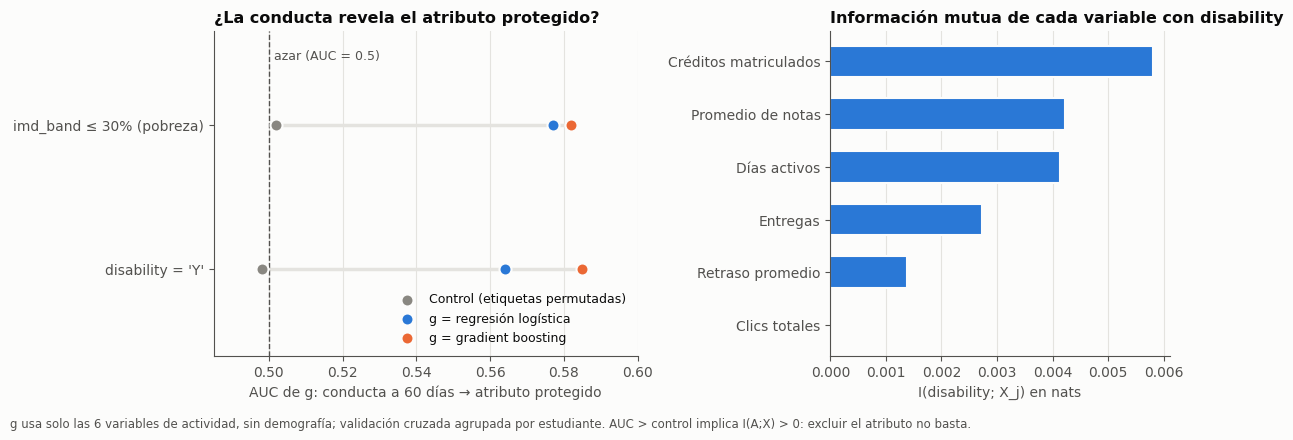

In [20]:
from matplotlib.lines import Line2D

NOMBRES = {
    "studied_credits": "Créditos matriculados", "promedio_notas_60d": "Promedio de notas",
    "dias_activos_60d": "Días activos", "entregas_60d": "Entregas",
    "retraso_promedio_60d": "Retraso promedio", "total_clics_60d": "Clics totales",
}
NEUTRO = "#898781"
tabla_p = proxies.set_index("atributo_protegido")
pos = np.arange(len(tabla_p))
cols_auc = ["AUC_control_permutado", "AUC_LogReg", "AUC_GradBoost"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax1.grid(False)
ax1.grid(axis="x")
ax1.hlines(pos, tabla_p[cols_auc].min(axis=1), tabla_p[cols_auc].max(axis=1), color=REJILLA, linewidth=2.5, zorder=1)
for col, color, etiqueta in [("AUC_control_permutado", NEUTRO, "Control (etiquetas permutadas)"),
                             ("AUC_LogReg", SERIE_1, "g = regresión logística"),
                             ("AUC_GradBoost", SERIE_2, "g = gradient boosting")]:
    ax1.scatter(tabla_p[col], pos, s=75, color=color, edgecolor=FONDO, linewidth=1.5, zorder=3, label=etiqueta)
ax1.axvline(0.5, color=TINTA_2, linestyle="--", linewidth=1)
ax1.text(0.5015, len(pos) - 0.55, "azar (AUC = 0.5)", fontsize=9, color=TINTA_2)
ax1.set_yticks(pos, tabla_p.index)
ax1.set_ylim(-0.6, len(pos) - 0.35)
ax1.set_xlim(0.485, 0.60)
ax1.set_xlabel("AUC de g: conducta a 60 días → atributo protegido")
ax1.set_title("¿La conducta revela el atributo protegido?")
ax1.legend(loc="lower right", fontsize=9)

mi_plot = mi.rename(index=NOMBRES).sort_values()
ax2.grid(False)
ax2.grid(axis="x")
ax2.set_axisbelow(True)
ax2.barh(mi_plot.index, mi_plot.values, height=0.6, color=SERIE_1, edgecolor=FONDO, linewidth=1.5)
ax2.set_xlabel("I(disability; X_j) en nats")
ax2.set_title("Información mutua de cada variable con disability")

fig.text(0.01, -0.03, "g usa solo las 6 variables de actividad, sin demografía; validación cruzada agrupada por estudiante. "
         "AUC > control implica I(A;X) > 0: excluir el atributo no basta.", fontsize=8.5, color=TINTA_2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/prueba_proxies.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
con.close()